
# Week 2 — Pricing Options

## 1. Trading Strategies and No-Arbitrage

A valid trading strategy should satisfy the following conditions:

- **Non-anticipating:** Trading decisions must use only information available at the current time, without knowledge of future outcomes.
- **Market-based:** Decisions depend only on market information and permitted trading assets, not on unrelated external random events.
- **Self-financing:** After the initial investment, changes in portfolio holdings are financed through trading within the portfolio, without additional deposits or withdrawals.
- **No-Arbitrage:** The market should not permit a zero-cost strategy with non-negative terminal payoff in every possible state and strictly positive payoff in at least one state.

**No-Arbitrage Principle:** Two portfolios with identical future payoffs in every state must have the same initial price. Otherwise, buying the cheaper portfolio and selling the more expensive one creates an arbitrage opportunity.

## 2. Complete Markets and Replication

A market is **complete** if every contingent claim (derivative payoff) can be replicated using a self-financing trading strategy involving the available assets.

In a one-period Binomial Model, we use:

- $S_0$: Initial stock price
- $u,d$: Stock up and down factors, with $u>d$
- $B_0,B_1$: Bond values at times 0 and 1
- $r$: One-period risk-free interest rate, with $B_1=B_0(1+r)$
- $\Phi_1^u, \Phi_1^d$: Derivative payoffs in the up and down states
- $\alpha_0,\beta_0$: Units of stock and bond held in the replicating portfolio

The stock prices at maturity are:

$$
S_1^u=S_0u,\qquad S_1^d=S_0d
$$

A portfolio holding $\alpha_0$ stocks and $\beta_0$ bonds has value:

$$
V_t(\phi)=\alpha_0S_t+\beta_0B_t
$$

**Replication requires the portfolio to match the derivative payoff in both states:**

$$
\begin{cases}
\alpha_0S_0u+\beta_0B_0(1+r)=\Phi_1^u\\
\alpha_0S_0d+\beta_0B_0(1+r)=\Phi_1^d
\end{cases}
$$

Subtracting the equations gives the stock holding, also called the **Hedge Ratio (Delta)**:

$$
\boxed{\alpha_0=\frac{\Phi_1^u-\Phi_1^d}{S_0(u-d)}}
$$

The required bond holding is:

$$
\boxed{\beta_0=\frac{u\Phi_1^d-d\Phi_1^u}{B_0(1+r)(u-d)}}
$$

By No-Arbitrage, the derivative's fair price equals the initial replication cost:

$$
\boxed{P=V_0(\phi)=\alpha_0S_0+\beta_0B_0}
$$

A negative bond position represents borrowing. A negative stock position represents short-selling.

## 3. Example — Pricing a European Call

Consider a one-period European Call Option:

$$
S_0=100,\quad K=100,\quad u=1.01,\quad d=0.99,\quad r=0
$$

The call payoff is:

$$
\Phi_1=\max(S_1-K,0)
$$

| State | Stock Price | Call Payoff |
|---|---:|---:|
| Up | £101 | £1 |
| Down | £99 | £0 |

Suppose the real-world probability of an upward move is $p=0.6$.

The expected payoff under this probability is:

$$
\mathbb{E}_p[\Phi_1]=0.6(1)+0.4(0)=0.6
$$

**However, £0.60 is not the no-arbitrage option price.**

Instead, construct a replicating portfolio:

$$
\begin{cases}
101\alpha_0+\beta_0B_1=1\\
99\alpha_0+\beta_0B_1=0
\end{cases}
$$

Subtracting:

$$
2\alpha_0=1
\quad\Rightarrow\quad
\boxed{\alpha_0=0.5}
$$

Substituting into either equation:

$$
\boxed{\beta_0B_1=-49.5}
$$

Since $r=0$, the bond position has the same value at times 0 and 1.

The replication strategy is therefore:

- Buy 0.5 shares, costing £50.
- Borrow £49.50 at the risk-free rate.
- Net initial investment: £0.50.

Check the terminal payoffs:

$$
\begin{aligned}
\text{Up: }&0.5(101)-49.5=1\\
\text{Down: }&0.5(99)-49.5=0
\end{aligned}
$$

The portfolio exactly replicates the call in both states, so:

$$
\boxed{C_0=0.5}
$$

**Why not £0.60?** If the call traded for £0.60, we could short the call for £0.60 and buy its replicating portfolio for £0.50. The £0.10 difference would be an immediate arbitrage profit, with the future liability fully hedged.

An equivalent approach is to hold **one long call and short 0.5 shares**. This creates the same terminal portfolio value of $-49.5$ in both states, allowing the call price to be determined using the risk-free asset.

## 4. Stock Price Tree — Python Practice

Reproduce a one-period Binomial Stock Tree using Matplotlib.

The plotting function should accept:

- $S_0$: Initial stock price
- $u$: Up factor
- $d$: Down factor
- $N$: Number of periods
- $p$: Optional real-world upward probability

For the example above, the tree should display:

$$
100
\begin{cases}
\longrightarrow 101 & \text{Up}\\
\longrightarrow 99 & \text{Down}
\end{cases}
$$

The following Python implementation visualises a recombining binomial stock price tree over $N$ time steps.



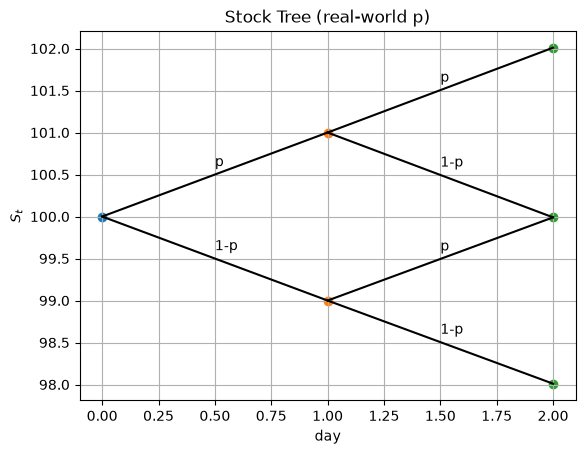

In [6]:
import matplotlib.pyplot as plt

def draw_tree_lr(S0, u, d, N, p=None, title="Stock Tree (real-world p)"):   # N: number of time steps
    levels = [[S0 * (u**j) * (d**(i-j)) for j in range(i+1)] for i in range(N+1)]
    plt.figure()

    for i in range(N):
        for j in range(i+1):
            x0, y0 = i, levels[i][j]
            x1u, y1u = i+1, levels[i+1][j+1]
            x1d, y1d = i+1, levels[i+1][j]
            plt.plot([x0,x1u],[y0,y1u],color='black') 
            plt.plot([x0,x1d],[y0,y1d],color='black')

            if p is not None:
                xu, yu = (x0+x1u)/2, (y0+y1u)/2 + 2.0
                xd, yd = (x0+x1d)/2, (y0+y1d)/2 + 0.5
                plt.text(xu, yu, f"p={p:.2f}", fontsize=10)
                plt.text(xd, yd, f"1-p={1-p:.2f}", fontsize=10)
            else:
                xu, yu = (x0+x1u)/2, (y0+y1u)/2 + 0.1
                xd, yd = (x0+x1d)/2, (y0+y1d)/2 + 0.1
                plt.text(xu, yu, f"p", fontsize=10)
                plt.text(xd, yd, f"1-p", fontsize=10)
    for i in range(N+1):
        xs=[i]*(i+1)
        ys=levels[i]
        plt.scatter(xs, ys)
    
    plt.title(title) 
    plt.xlabel("step n")
    plt.ylabel("$S_t$")
    plt.grid(True)
    plt.show()

draw_tree_lr(100, 1.01, 0.99, 2)
    

## 5. Replication — General Pricing Formula


Substituting the replication holdings into the initial cost gives:

$$
\begin{aligned}
P &= \alpha_0 S_0 + \beta_0 B_0 \\
  &= \left(\frac{\Phi_1^u-\Phi_1^d}{S_0(u-d)}\right)S_0
   + \left(\frac{u\Phi_1^d-d\Phi_1^u}{B_0(1+r)(u-d)}\right)B_0 \\
  &= \frac{\Phi_1^u-\Phi_1^d}{u-d}
   + \frac{u\Phi_1^d-d\Phi_1^u}{(1+r)(u-d)},
   \qquad \text{since } \frac{S_0}{S_0}=1 \text{ and } \frac{B_0}{B_0}=1.
\end{aligned}
$$

Rearranging:

$$
\begin{aligned}
P
&= \frac{1}{1+r}
\left[
\frac{(1+r)-d}{u-d}\Phi_1^u
+
\frac{u-(1+r)}{u-d}\Phi_1^d
\right]
\end{aligned}
$$

Define the risk-neutral probability:

$$
\boxed{p^*=\frac{(1+r)-d}{u-d}}
$$

Then:

$$
1-p^*=\frac{u-(1+r)}{u-d}
$$

Therefore:

$$
\boxed{
P=\frac{1}{1+r}
\left[p^*\Phi_1^u+(1-p^*)\Phi_1^d\right]
}
$$


## 6. Real-World Probability vs Risk-Neutral Probability

| | Real-World Probability $p$ | Risk-Neutral Probability $p^*$ |
|---|---|---|
| Meaning | Probability of an actual market outcome | Pricing probability derived from no-arbitrage |
| Purpose | Describes the assumed evolution of stock prices | Determines arbitrage-free derivative prices |
| Determination | Real-world model or statistical estimation | $p^*=\frac{1+r-d}{u-d}$ |
| Expected stock growth | Depends on the physical probability $p$ | Equals the risk-free growth factor |

The real-world probability $p$ and risk-neutral probability $p^*$ serve different purposes and need not be equal.

Under the risk-neutral measure:

$$
\begin{aligned}
\mathbb{E}_{p^*}[S_1]
&=p^*S_0u+(1-p^*)S_0d\\
&=(1+r)S_0
\end{aligned}
$$

Hence:

$$
\boxed{\mathbb{E}_{p^*}[S_1]=(1+r)S_0}
$$

Under the risk-neutral measure, the stock's **expected return equals the risk-free rate**. This does not mean the stock becomes risk-free or that its real-world expected return equals $r$.

## 7. No-Arbitrage Condition

For $p^*$ to be a valid probability strictly between 0 and 1:

$$
0<p^*<1
$$

Since $u>d$, this is equivalent to:

$$
\boxed{d<1+r<u}
$$

**Financial interpretation:**

The risk-free growth factor must lie strictly between the stock's down and up factors.

- If $1+r\le d$, the stock performs at least as well as the bond in every state. Buy the stock and borrow at the risk-free rate.
- If $u\le1+r$, the bond performs at least as well as the stock in every state. Short the stock and invest the proceeds in the bond.

In either case, the resulting strategy provides an arbitrage opportunity, assuming both states are possible and the required trades are permitted.

Thus, in the standard one-period binomial model:

$$
\boxed{\text{No Arbitrage}\iff d<1+r<u}
$$

## 8. Risk-Neutral Pricing Theorem

The arbitrage-free price of a replicable one-period derivative is its **discounted expected payoff under the risk-neutral probability**:

$$
\boxed{
P=\mathbb{E}_{p^*}\left[\frac{\Phi_1}{1+r}\right]
=\frac{1}{1+r}\mathbb{E}_{p^*}[\Phi_1]
}
$$

For our European Call:

$$
p^*=\frac{1-0.99}{1.01-0.99}=0.5
$$

Therefore:

$$
C_0=\frac{1}{1+0}\left[0.5(1)+0.5(0)\right]
=\boxed{0.5}
$$

This agrees with the replication result.

**Key takeaway:**

$$
\boxed{
\text{Replication}\longrightarrow\text{No-Arbitrage Price}
\longrightarrow\text{Risk-Neutral Pricing}
}
$$

Replication and risk-neutral pricing are two equivalent ways of calculating the fair option price in this complete one-period binomial market.



## 9. Multi-Period Binomial Option Pricing

The One-Period Binomial Model extends naturally to multiple time steps by applying replication and risk-neutral pricing at each node.

**Dynamic Replication**

For a derivative with terminal payoff $\Phi_T$, we construct a self-financing trading strategy:

$$
\phi=(\alpha_0,\ldots,\alpha_{T-1},\beta_0,\ldots,\beta_{T-1})
$$

where $\alpha_t$ and $\beta_t$ represent the stock and bond holdings chosen using information available at time $t$.

At maturity, the portfolio replicates the derivative payoff:

$$
\Phi_T=\alpha_{T-1}S_T+\beta_{T-1}B_T
$$

At each node, the hedge positions can be found by solving the same two linear equations as in the one-period model:

$$
\boxed{\alpha_t=\frac{P_{t+1}^u-P_{t+1}^d}{S_t(u-d)}}
$$

$$
\boxed{\beta_t=\frac{uP_{t+1}^d-dP_{t+1}^u}{B_t(1+r)(u-d)}}
$$

Here, $P_{t+1}^u$ and $P_{t+1}^d$ are the derivative values at the two successor nodes. At maturity, $P_T=\Phi_T$.

**Backward Induction**

Stock prices evolve forward through the binomial tree, while option prices are calculated backwards from the terminal payoff.

Starting with:

$$
P_T=\Phi_T
$$

The risk-neutral pricing recursion at each earlier node is:

$$
\boxed{
P_t=\frac{1}{1+r}
\left[p^*P_{t+1}^u+(1-p^*)P_{t+1}^d\right]
}
$$

where:

$$
p^*=\frac{1+r-d}{u-d}
$$

and the no-arbitrage condition remains:

$$
d<1+r<u
$$

**Multi-Period Risk-Neutral Pricing**

Applying the one-period pricing formula repeatedly and using the Tower Property of Conditional Expectation gives:

$$
\boxed{
P_t=\frac{1}{(1+r)^{T-t}}
\mathbb E_{p^*}[\Phi_T\mid\mathcal F_t]
}
$$

where $\mathcal F_t$ represents the market information available at time $t$.

In particular, the initial option price is:

$$
\boxed{
P_0=\frac{1}{(1+r)^T}\mathbb E_{p^*}[\Phi_T]
}
$$

These formulas assume constant one-period parameters $u,d,r$ and a replicable European-style terminal payoff.

**Key Takeaways**

- **Stock Tree:** Constructed forward from $S_0$ to $S_T$.
- **Option Price Tree:** Calculated backwards from $\Phi_T$ to $P_0$.
- **Dynamic Hedging:** The stock and bond holdings may change at different nodes and times.
- **Risk-Neutral Pricing:** The option price is the discounted expected terminal payoff under $p^*$, not the physical probability $p$.
- **Backward Induction and Direct Expectation:** Two equivalent pricing approaches in the standard complete binomial market.




In [18]:
import matplotlib.pyplot as plt


def draw_stock_and_option_trees(
    S0, u, d, N,
    V_terminal,
    p=None,
    title_left="Stock Tree",
    title_right="Option Value Tree",
    leaf_fmt="{:.2f}",
    label_prefix="P"
):
    """
    Plot a stock price tree and its corresponding option value tree.

    Parameters
    ----------
    S0 : float
        Initial stock price.
    u, d : float
        Up and down factors.
    N : int
        Number of time steps.
    V_terminal : list or tuple
        Terminal option payoffs, ordered from all-down to all-up.
        Must contain N+1 values.
    p : float, optional
        Real-world probability of an upward movement.
    """

    # Build the stock price tree
    S_levels = [
        [S0 * u**j * d**(i-j) for j in range(i+1)]
        for i in range(N+1)
    ]

    # Validate terminal payoffs
    if not hasattr(V_terminal, "__len__") or len(V_terminal) != N+1:
        raise ValueError(f"V_terminal must contain {N+1} values.")

    fig, (axS, axV) = plt.subplots(
        1, 2, figsize=(12, 5), constrained_layout=True
    )

    # Calculate label offset
    ymin = min(min(level) for level in S_levels)
    ymax = max(max(level) for level in S_levels)
    yoff = 0.06 * (ymax - ymin) if ymax > ymin else 0.05

    # ---------- Stock Price Tree ----------
    for i in range(N):
        for j in range(i+1):
            x0, y0 = i, S_levels[i][j]
            x1u, y1u = i+1, S_levels[i+1][j+1]
            x1d, y1d = i+1, S_levels[i+1][j]

            axS.plot([x0, x1u], [y0, y1u], color="black", linewidth=1)
            axS.plot([x0, x1d], [y0, y1d], color="black", linewidth=1)

            xu, yu = (x0+x1u)/2, (y0+y1u)/2 + yoff
            xd, yd = (x0+x1d)/2, (y0+y1d)/2 - yoff

            if p is not None:
                axS.text(xu, yu, f"p={p:.2f}", fontsize=9, ha="center")
                axS.text(xd, yd, f"1-p={1-p:.2f}", fontsize=9, ha="center")
            else:
                axS.text(xu, yu, "p", fontsize=9, ha="center")
                axS.text(xd, yd, "1-p", fontsize=9, ha="center")

    for i in range(N+1):
        xs = [i] * (i+1)
        ys = S_levels[i]
        axS.scatter(xs, ys, s=25)

    axS.set_title(title_left)
    axS.set_xlabel("step n")
    axS.set_ylabel("$S_n$")
    axS.grid(True, alpha=0.3)

    # ---------- Option Value Tree ----------
    for i in range(N):
        for j in range(i+1):
            x0, y0 = i, S_levels[i][j]
            x1u, y1u = i+1, S_levels[i+1][j+1]
            x1d, y1d = i+1, S_levels[i+1][j]

            axV.plot([x0, x1u], [y0, y1u], color="black", linewidth=1)
            axV.plot([x0, x1d], [y0, y1d], color="black", linewidth=1)

    # Label internal nodes and terminal payoffs
    pk = 0

    for i in range(N+1):
        xs = [i] * (i+1)
        ys = S_levels[i]

        axV.scatter(xs, ys, s=25)

        for j in range(i+1):
            if i < N:
                axV.text(
                    xs[j], ys[j] + yoff,
                    f"${label_prefix}_{pk}$",
                    fontsize=10, ha="center", va="bottom"
                )
                pk += 1
            else:
                v = V_terminal[j]
                label = leaf_fmt.format(v) if isinstance(v, (int, float)) else str(v)

                axV.text(
                    xs[j], ys[j] + yoff,
                    label,
                    fontsize=9, ha="center", va="bottom"
                )

    axV.set_title(title_right)
    axV.set_xlabel("step n")
    axV.set_ylabel("Stock price (tree layout)")
    axV.grid(True, alpha=0.3)
    axV.set_yticklabels([])

    plt.show();

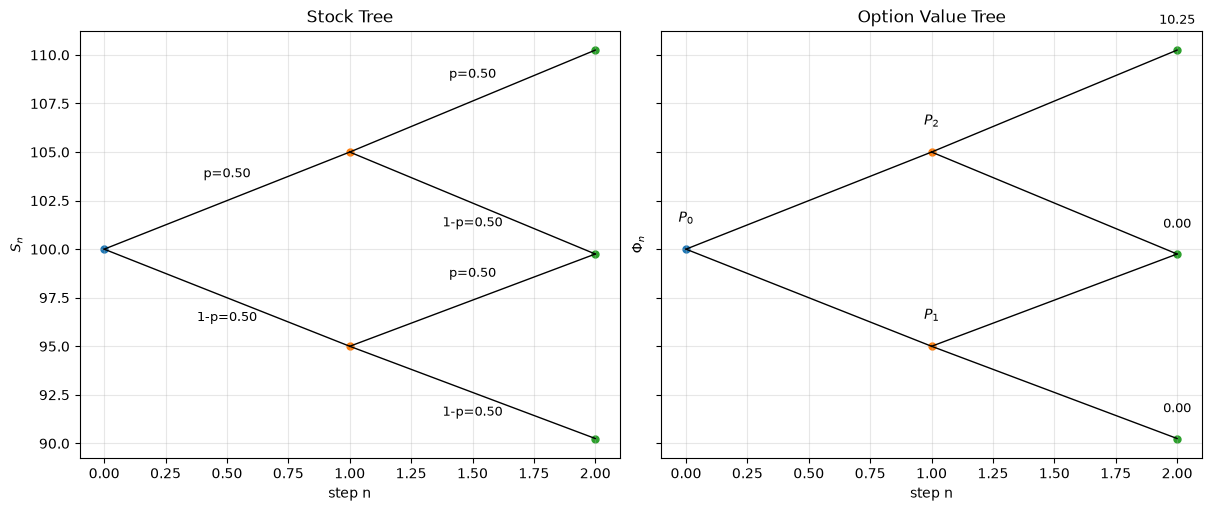

In [14]:
draw_stock_and_option_trees(100, 1.05, 0.95, 2, [0.0, 0.0, 10.25] , p=0.5)


### Q&A — Expected Profit vs Arbitrage

**Q: If an option's expected payoff under the real-world probability exceeds its no-arbitrage price, does this create an arbitrage opportunity? Must arbitrage transactions occur at the same time?**

**Answer:**

No. A positive expected profit does not necessarily imply an arbitrage opportunity.

**1. Positive Expected Profit Is Not Arbitrage**

Consider a European Call Option with:

- No-arbitrage price: $C_0 = £5.25$
- Real-world probability of an upward stock movement: $p = 0.6$
- Terminal payoff: £21 if the stock rises twice, and £0 otherwise
- Risk-free interest rate: $r = 0$

The expected terminal payoff under the real-world probability is:

$$
\mathbb{E}_p[\Phi_2]=0.6^2(21)=£7.56
$$

Hence, the expected net profit from buying the call is:

$$
\mathbb{E}_p[\text{Profit}]=7.56-5.25=£2.31
$$

However, this is **not arbitrage** because the investor faces potential losses:

- If the stock rises twice, the realised profit is $21-5.25=£15.75$.
- Otherwise, the call expires worthless, resulting in a loss of £5.25.

The positive £2.31 represents an **expected profit**, not a guaranteed profit.

**2. What Constitutes a Genuine Arbitrage Opportunity?**

Suppose the market price of the same call is £7.56, while its replicating portfolio costs only £5.25.

An arbitrageur can:

- Short the overpriced call and receive £7.56.
- Buy the replicating portfolio for £5.25.
- Lock in an initial cash surplus of £2.31.

Because the portfolio replicates the call's payoff in every possible state, the future liability from the short call is fully hedged.

This constitutes an arbitrage opportunity under the model's assumptions.

**3. Does Arbitrage Require Simultaneous Settlement?**

No. Arbitrage does not require all transactions or cash flows to occur at the same time.

An arbitrage strategy can involve future trading and settlement, provided that:

- It requires no positive net initial investment.
- Its terminal payoff is non-negative in every possible state.
- It produces a strictly positive payoff in at least one possible state.

In the replication example, the strategy is established at time 0, but the hedge may be dynamically rebalanced until maturity.

**Key Distinction**

$$
\boxed{\text{Positive Expected Profit}\neq\text{Arbitrage Profit}}
$$

A positive expected profit depends on the probability distribution of future outcomes and may involve losses.

Arbitrage exploits a pricing inconsistency and does not depend on predicting which market outcome will occur.

**Conclusion:** The defining feature of arbitrage is not the absence of a time interval, but the absence of downside risk in a self-financing, zero-net-investment strategy.
